# InfoVAE

Balance reconstruction, per-example information retention, and aggregate prior matching. This notebook demonstrates one MMD-based InfoVAE formulation; variants and coefficient conventions differ.

This standalone notebook includes its own MNIST setup, model components, objective, and training step. Run the cells from top to bottom. The training cell runs 50 epochs on the full MNIST training split. A GPU runtime is recommended in Colab.

## Shared MNIST data and VAE components

The baseline is a small MLP VAE with a diagonal Gaussian posterior and Bernoulli image decoder. We reuse it where the variant changes the objective rather than the architecture.

In [1]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

class MLPVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu = nn.Linear(400, latent_dim); self.logvar = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_terms(recon, x, mu, logvar):
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return rec, kl

def sample_batch(loader):
    return next(iter(loader))[0].to(device)

Using device: cuda


## Implementation

The following cell defines this variant's model-specific objective and optimization step.

## 5. InfoVAE with MMD matching

InfoVAE balances reconstruction, information retained in `z`, and aggregate prior matching. Formulations vary. This notebook uses one MMD-based minimization form: `reconstruction + (1-alpha)*KL + (alpha+lambda-1)*MMD(q(z),p(z))`. The chosen settings below are an illustrative configuration, not universal defaults. InfoVAE may help when latent codes are underused, but does not guarantee prevention of posterior collapse.

In [2]:
def mmd_rbf(x, y, scales=(0.5, 1.0, 2.0, 4.0)):
    """Biased multi-scale RBF MMD estimate between two sample batches."""
    xx = torch.cdist(x, x).square()
    yy = torch.cdist(y, y).square()
    xy = torch.cdist(x, y).square()
    k_xx = sum(torch.exp(-xx / (2 * scale)) for scale in scales) / len(scales)
    k_yy = sum(torch.exp(-yy / (2 * scale)) for scale in scales) / len(scales)
    k_xy = sum(torch.exp(-xy / (2 * scale)) for scale in scales) / len(scales)
    return k_xx.mean() + k_yy.mean() - 2 * k_xy.mean()

info_vae = MLPVAE().to(device); info_optim = torch.optim.Adam(info_vae.parameters(), lr=1e-3)

def infovae_train_step(x, alpha=0.0, lambda_mmd=10.0):
    x = x.to(device); recon, mu, logvar = info_vae(x); z = info_vae.reparameterize(mu, logvar)
    rec, kl = vae_terms(recon, x, mu, logvar)
    aggregate_match = mmd_rbf(z, torch.randn_like(z))
    loss = rec + (1 - alpha) * kl + (alpha + lambda_mmd - 1) * aggregate_match
    info_optim.zero_grad(); loss.backward(); info_optim.step()
    return {'reconstruction': rec.item(), 'kl': kl.item(), 'mmd': aggregate_match.item(), 'loss': loss.item()}

# Example: metrics = infovae_train_step(sample_batch(train_loader))

## Full training — 50 epochs

This runs on the full MNIST training split using the model-specific objective above. In Colab, select a GPU runtime for faster training. The final checkpoint includes model weights, optimizer state, and epoch metrics.

In [3]:
from pathlib import Path

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    totals = {}
    for images, _ in train_loader:
        batch_metrics = infovae_train_step(images)
        for name, value in batch_metrics.items():
            totals[name] = totals.get(name, 0.0) + float(value) * images.size(0)
    epoch_metrics = {name: value / len(train_loader.dataset) for name, value in totals.items()}
    history.append(epoch_metrics)
    summary = " | ".join(f"{name}={value:.4f}" for name, value in epoch_metrics.items())
    print(f"Epoch {epoch:02d}/{epochs} | {summary}")

checkpoint = {
    "model": info_vae.state_dict(),
    "optimizers": {"info_optim": info_optim.state_dict()},
    "epochs": epochs,
    "history": history
}
checkpoint_path = Path("13_InfoVAE_50_epochs.pt")
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint to {checkpoint_path.resolve()}")


Epoch 01/50 | reconstruction=150.4433 | kl=14.7032 | mmd=0.0219 | loss=165.3434
Epoch 02/50 | reconstruction=100.1030 | kl=21.0189 | mmd=0.0192 | loss=121.2944
Epoch 03/50 | reconstruction=92.7886 | kl=22.0436 | mmd=0.0183 | loss=114.9968
Epoch 04/50 | reconstruction=89.5929 | kl=22.4943 | mmd=0.0177 | loss=112.2468
Epoch 05/50 | reconstruction=87.6498 | kl=22.7363 | mmd=0.0175 | loss=110.5432
Epoch 06/50 | reconstruction=86.3484 | kl=22.9010 | mmd=0.0173 | loss=109.4050
Epoch 07/50 | reconstruction=85.4122 | kl=23.0718 | mmd=0.0171 | loss=108.6381
Epoch 08/50 | reconstruction=84.6271 | kl=23.1596 | mmd=0.0171 | loss=107.9403
Epoch 09/50 | reconstruction=84.0313 | kl=23.2651 | mmd=0.0170 | loss=107.4490
Epoch 10/50 | reconstruction=83.5669 | kl=23.3109 | mmd=0.0170 | loss=107.0303
Epoch 11/50 | reconstruction=83.1347 | kl=23.4103 | mmd=0.0169 | loss=106.6969
Epoch 12/50 | reconstruction=82.7190 | kl=23.4707 | mmd=0.0169 | loss=106.3414
Epoch 13/50 | reconstruction=82.4364 | kl=23.4877 

## Inspect reconstruction, prior samples, and aggregate matching

Use these plots alongside the objective metrics; no single number captures reconstruction quality, prior matching, latent use, and sample quality.

Aggregate posterior MMD estimate on this batch: 0.0178


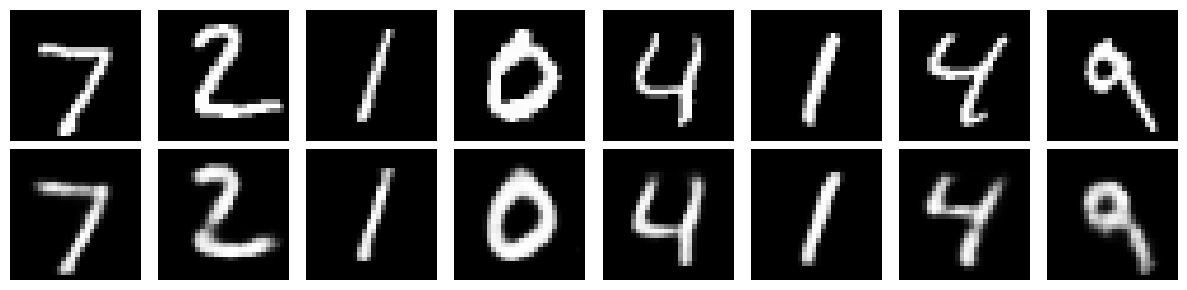

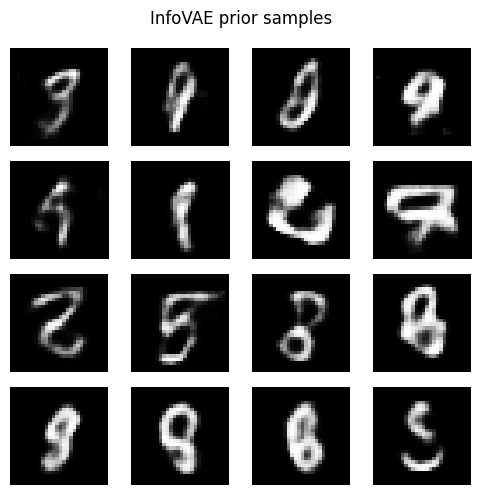

In [5]:
x = sample_batch(test_loader)[:8]
info_vae.eval()
with torch.no_grad():
    mu, logvar = info_vae.encode(x); recon = info_vae.decode(info_vae.reparameterize(mu, logvar))
    prior_samples = info_vae.decode(torch.randn(16, info_vae.latent_dim, device=device))
    z = info_vae.reparameterize(*info_vae.encode(sample_batch(test_loader)))
    mmd_value = mmd_rbf(z, torch.randn_like(z)).item()
print(f'Aggregate posterior MMD estimate on this batch: {mmd_value:.4f}')
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0].cpu(), cmap='gray'); ax.axis('off')
plt.suptitle('InfoVAE prior samples'); plt.tight_layout(); plt.show()